TABLE 1: Model comparison (test n=147). Old results = 200-image dataset, tiny test, ResNet18 old = leakage wala.
                     Model  Val F1 (%)  Test Acc (%)  Test Macro F1 (%)  Old Acc (%)  Old F1 (%)  95% CI (+/- %)  Val-Test gap (F1)
       Logistic Regression       44.26         45.58              45.22         35.0       35.50             8.1               -1.0
             Random Forest       48.40         36.05              35.97         50.0       50.36             7.8               12.4
                 SVM (RBF)       45.61         40.14              39.80         50.0       52.42             7.9                5.8
          CNN from scratch       46.71         38.10              37.72         37.5       37.00             7.9                9.0
      ResNet18 frozen + fc       49.54         52.38              52.65         67.5       67.36             8.1               -3.1
ResNet18 layer4 fine-tuned       57.46         53.06              53.20          NaN         Na

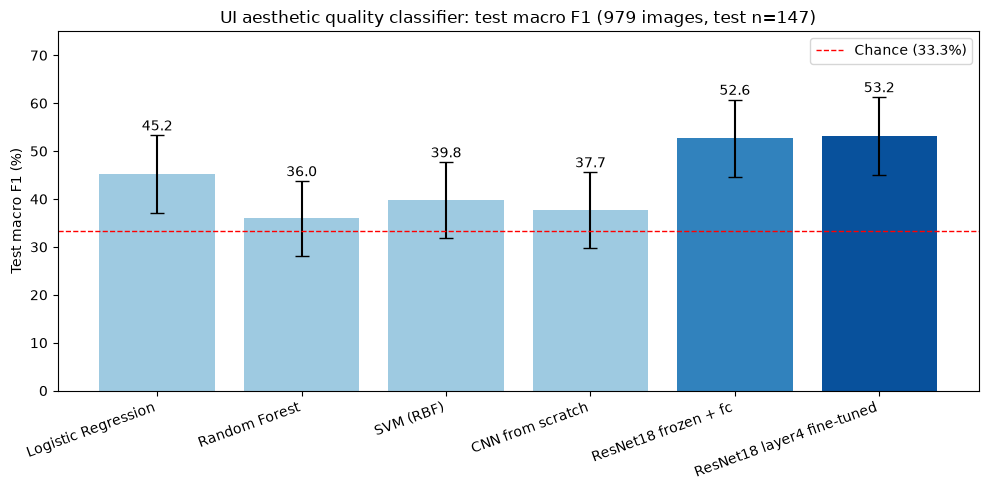


Saved in: C:\Projects\Internship_Learning\docs


In [2]:
# ============================================================
# 08_results_comparison_v2 - Cell 1
# Final test results table, old vs new, source-wise table, chart; CSV/PNG docs folder me save
# ============================================================

# Pandas aur NumPy tables/maths ke liye
import pandas as pd
import numpy as np

# Matplotlib chart ke liye
import matplotlib.pyplot as plt

# os module paths ke liye
import os

# Paths: project aur docs folder
PROJECT_DIR = r"C:\Projects\Internship_Learning"
DOCS_DIR = os.path.join(PROJECT_DIR, "docs")
os.makedirs(DOCS_DIR, exist_ok=True)

# Test set ka size (accuracy ke confidence interval ke liye)
N_TEST = 147

# ---------- Table 1: naye results (979 images, test n=147) + purane results ----------
# Val F1 = best checkpoint/tuned model ka validation macro F1 (selection ke liye use hua)
# Test = test set pe EK baar evaluate kiya hua result
rows = [
    # Model, val macro F1, test acc, test macro F1, old acc, old macro F1
    ("Logistic Regression", 44.26, 45.58, 45.22, 35.0, 35.5),
    ("Random Forest", 48.40, 36.05, 35.97, 50.0, 50.36),
    ("SVM (RBF)", 45.61, 40.14, 39.80, 50.0, 52.42),
    ("CNN from scratch", 46.71, 38.10, 37.72, 37.5, 37.0),
    ("ResNet18 frozen + fc", 49.54, 52.38, 52.65, 67.5, 67.36),
    ("ResNet18 layer4 fine-tuned", 57.46, 53.06, 53.20, np.nan, np.nan),
]
results = pd.DataFrame(rows, columns=["Model", "Val F1 (%)", "Test Acc (%)", "Test Macro F1 (%)", "Old Acc (%)", "Old F1 (%)"])

# Test accuracy ka 95% confidence interval (normal approximation): +/- 1.96 * sqrt(p(1-p)/n)
p = results["Test Acc (%)"] / 100
results["95% CI (+/- %)"] = (1.96 * np.sqrt(p * (1 - p) / N_TEST) * 100).round(1)

# Val -> Test gap (positive = val optimistic tha)
results["Val-Test gap (F1)"] = (results["Val F1 (%)"] - results["Test Macro F1 (%)"]).round(1)

# Table print
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
print("TABLE 1: Model comparison (test n=147). Old results = 200-image dataset, tiny test, ResNet18 old = leakage wala.")
print(results.to_string(index=False))

# ---------- Table 2: source-wise test macro F1 (n: old 30, b1 19, b2 42, b3 56) ----------
src = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "SVM (RBF)", "CNN from scratch", "ResNet18 frozen + fc", "ResNet18 layer4 fine-tuned"],
    "old (n=30)": [53.1, 30.9, 47.5, 38.3, 37.1, 51.1],
    "b1 (n=19)": [46.6, 34.8, 39.4, 42.1, 53.0, 51.6],
    "b2 (n=42)": [40.4, 29.5, 33.8, 33.2, 54.6, 47.6],
    "b3 (n=56)": [41.2, 36.3, 38.1, 37.4, 58.3, 58.1],
})
print("\nTABLE 2: Source-wise test macro F1 (%). Chhote n ki wajah se sirf indication.")
print(src.to_string(index=False))

# ---------- Chart: test macro F1 (error bar = accuracy ka 95% CI) ----------
fig, ax = plt.subplots(figsize=(10, 5))

# Models ke naam aur values
names = results["Model"].tolist()
f1_vals = results["Test Macro F1 (%)"].tolist()
errs = results["95% CI (+/- %)"].tolist()

# Rang: ResNet models highlight (dark), baaki halka
colors = ["#9ecae1"] * 4 + ["#3182bd", "#08519c"]

# Bar chart with error bars
bars = ax.bar(names, f1_vals, yerr=errs, capsize=5, color=colors)

# Chance level line (3 classes me ~33.3%)
ax.axhline(33.3, color="red", linestyle="--", linewidth=1, label="Chance (33.3%)")

# Har bar ke upar value
for b, v, e in zip(bars, f1_vals, errs):
    ax.text(b.get_x() + b.get_width() / 2, v + e + 1, f"{v:.1f}", ha="center", fontsize=10)

# Labels aur title
ax.set_ylabel("Test macro F1 (%)")
ax.set_title("UI aesthetic quality classifier: test macro F1 (979 images, test n=147)")
ax.set_ylim(0, 75)
plt.xticks(rotation=20, ha="right")
ax.legend()
plt.tight_layout()

# Chart ko docs folder me PNG me save
CHART_PATH = os.path.join(DOCS_DIR, "results_comparison_v2.png")
plt.savefig(CHART_PATH, dpi=200)
plt.show()

# Dono tables CSV me save
results.to_csv(os.path.join(DOCS_DIR, "results_comparison_v2.csv"), index=False)
src.to_csv(os.path.join(DOCS_DIR, "results_sourcewise_v2.csv"), index=False)
print("\nSaved in:", DOCS_DIR)